# Lab 2 — Diffusion Models: UNet DDPM from Scratch
**COM SCI-X 455 · Week 2 · Megan Armani, PhD**

> Push to `genai-course/week2/`

---

## Setup

In [1]:
!pip install diffusers accelerate torch torchvision matplotlib --quiet

In [2]:
import torch, torch.nn as nn, numpy as np, matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Device:", DEVICE)

Device: cuda


## Note on Homework Extension
The **lab** trains on MNIST. Your **homework** extends to FashionMNIST:
```python
# One-line swap:
train_data = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
```
The UNet and training loop are identical. FashionMNIST is harder — observe how many epochs your model needs vs MNIST.

## Part 1 — Forward Process (Noise Schedule)
**Goal:** Implement the linear and cosine variance schedules and visualise what they do to an image.

In [3]:
def linear_schedule(T=1000, beta_start=1e-4, beta_end=0.02):
    return torch.linspace(beta_start, beta_end, T)

def cosine_schedule(T=1000, s=0.008):
    steps = torch.arange(T+1, dtype=torch.float32)
    f = torch.cos(((steps/T + s) / (1+s)) * torch.pi/2) ** 2
    alphas_bar = f / f[0]
    betas = 1 - (alphas_bar[1:] / alphas_bar[:-1])
    return torch.clamp(betas, 0, 0.999)

In [4]:
# TODO: Implement `q_sample(x0, t, betas)` - the closed-form forward process.
# Formula: x_t = sqrt(alpha_bar_t) * x0 + sqrt(1 - alpha_bar_t) * eps
# where eps ~ N(0,I) and alpha_bar_t = prod(1 - beta_i for i in 1..t)
# Hint: precompute alpha_bar from betas.
def q_sample(x0, t, betas, noise=None):
    alpha_bars = torch.cumprod(1 - betas.to(x0.device), dim=0)
    ab = alpha_bars[t].view(-1, 1, 1, 1)
    if noise is None:
        noise = torch.randn_like(x0)
    return ab.sqrt() * x0 + (1 - ab).sqrt() * noise, noise

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.75MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 135kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.30MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.6MB/s]


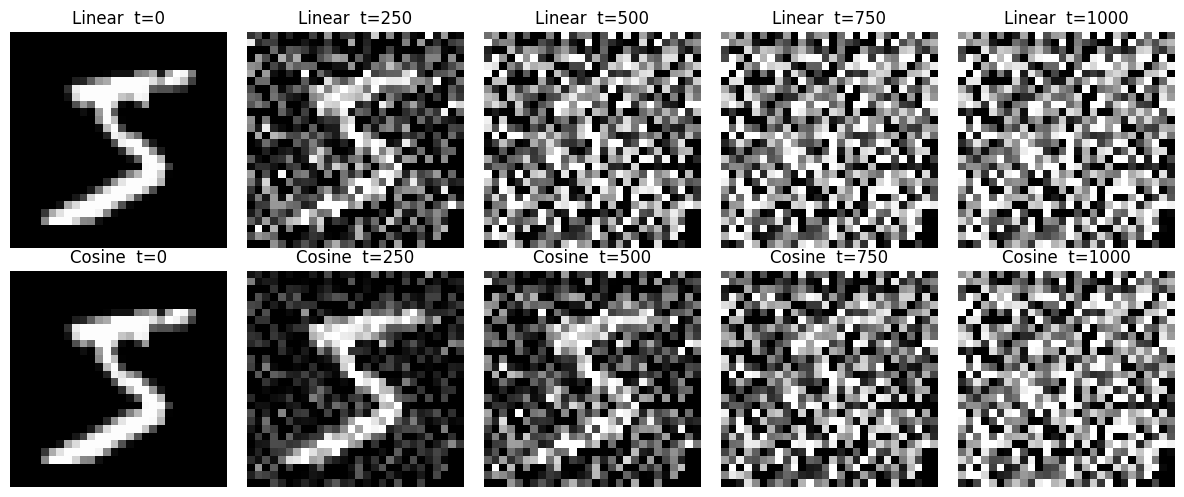

In [5]:
# TODO: Visualise the noising process: take one MNIST image, show it at t=0, 250, 500, 750, 1000
# for BOTH linear and cosine schedules side by side.
# Which schedule destroys fine detail faster?
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])   # pixels in [-1, 1]
train_data = datasets.MNIST(root='./data', train=True, download=True, transform=transform)

x0 = train_data[0][0].unsqueeze(0)
noise = torch.randn_like(x0)                 # same noise for both schedules
times = [0, 250, 500, 750, 1000]
schedules = {"Linear": linear_schedule(), "Cosine": cosine_schedule()}

fig, axes = plt.subplots(2, len(times), figsize=(12, 5))
for row, (name, betas) in enumerate(schedules.items()):
    for col, t in enumerate(times):
        if t == 0:
            xt = x0
        else:
            xt, _ = q_sample(x0, torch.tensor([t - 1]), betas, noise)   # t=1000 -> last index (999)
        axes[row, col].imshow(((xt[0, 0] + 1) / 2).clamp(0, 1), cmap="gray", vmin=0, vmax=1)
        axes[row, col].set_title(f"{name}  t={t}")
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

## Part 2 — U-Net Noise Predictor

In [6]:
class SinusoidalTimeEmb(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim
    def forward(self, t):
        half = self.dim // 2
        freqs = torch.exp(-torch.arange(half, device=t.device) * (torch.log(torch.tensor(10000.0)) / (half-1)))
        args  = t[:, None].float() * freqs[None]
        return torch.cat([torch.sin(args), torch.cos(args)], dim=-1)

class ResBlock(nn.Module):
    def __init__(self, ch, time_dim):
        super().__init__()
        self.conv1  = nn.Conv2d(ch, ch, 3, padding=1)
        self.conv2  = nn.Conv2d(ch, ch, 3, padding=1)
        self.time_mlp = nn.Linear(time_dim, ch)
        self.norm1  = nn.GroupNorm(8, ch)
        self.norm2  = nn.GroupNorm(8, ch)
    def forward(self, x, t_emb):
        h = self.norm1(x)
        h = torch.relu(self.conv1(h))
        h = h + self.time_mlp(t_emb)[:, :, None, None]
        h = self.norm2(h)
        return x + self.conv2(torch.relu(h))

In [7]:
# TODO: Build a UNet class with:
# - Encoder: 3 levels (32->64->128 channels), each with ResBlock + downsample
# - Bottleneck: ResBlock with time embedding
# - Decoder: 3 levels with skip connections + upsample
# - Time embedding fed to every ResBlock
# Input: (B, 1, 28, 28) noisy image + timestep t
# Output: (B, 1, 28, 28) predicted noise
import torch.nn.functional as F

class Up(nn.Module):
    """Upsample to the skip's size, reduce channels, merge the skip connection, then ResBlock."""
    def __init__(self, in_ch, out_ch, time_dim):
        super().__init__()
        self.reduce = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.merge  = nn.Conv2d(out_ch * 2, out_ch, 1)
        self.res    = ResBlock(out_ch, time_dim)
    def forward(self, x, skip, t_emb):
        x = F.interpolate(x, size=skip.shape[-2:], mode="nearest")
        x = self.reduce(x)
        x = self.merge(torch.cat([x, skip], dim=1))
        return self.res(x, t_emb)

class UNet(nn.Module):
    def __init__(self, time_dim=128):
        super().__init__()
        self.time_emb = nn.Sequential(
            SinusoidalTimeEmb(time_dim), nn.Linear(time_dim, time_dim), nn.ReLU())
        self.inp = nn.Conv2d(1, 32, 3, padding=1)
        # Encoder: ResBlock then strided-conv downsample (28 -> 14 -> 7 -> 4)
        self.enc1, self.down1 = ResBlock(32, time_dim),  nn.Conv2d(32, 64, 3, stride=2, padding=1)
        self.enc2, self.down2 = ResBlock(64, time_dim),  nn.Conv2d(64, 128, 3, stride=2, padding=1)
        self.enc3, self.down3 = ResBlock(128, time_dim), nn.Conv2d(128, 128, 3, stride=2, padding=1)
        # Bottleneck
        self.mid = ResBlock(128, time_dim)
        # Decoder
        self.up3 = Up(128, 128, time_dim)
        self.up2 = Up(128, 64, time_dim)
        self.up1 = Up(64, 32, time_dim)
        self.out = nn.Conv2d(32, 1, 3, padding=1)

    def forward(self, x, t):
        t_emb = self.time_emb(t)
        x = self.inp(x)
        s1 = self.enc1(x, t_emb);  x = self.down1(s1)
        s2 = self.enc2(x, t_emb);  x = self.down2(s2)
        s3 = self.enc3(x, t_emb);  x = self.down3(s3)
        x = self.mid(x, t_emb)
        x = self.up3(x, s3, t_emb)
        x = self.up2(x, s2, t_emb)
        x = self.up1(x, s1, t_emb)
        return self.out(x)

## Part 3 — Training Loop

--- linear schedule ---
Epoch 1/20: loss = 0.0652
Epoch 2/20: loss = 0.0326
Epoch 3/20: loss = 0.0291
Epoch 4/20: loss = 0.0275
Epoch 5/20: loss = 0.0269
Epoch 6/20: loss = 0.0258
Epoch 7/20: loss = 0.0256
Epoch 8/20: loss = 0.0254
Epoch 9/20: loss = 0.0251
Epoch 10/20: loss = 0.0246
Epoch 11/20: loss = 0.0243
Epoch 12/20: loss = 0.0245
Epoch 13/20: loss = 0.0243
Epoch 14/20: loss = 0.0244
Epoch 15/20: loss = 0.0238
Epoch 16/20: loss = 0.0239
Epoch 17/20: loss = 0.0237
Epoch 18/20: loss = 0.0236
Epoch 19/20: loss = 0.0235
Epoch 20/20: loss = 0.0236
--- cosine schedule ---
Epoch 1/20: loss = 0.0997
Epoch 2/20: loss = 0.0540
Epoch 3/20: loss = 0.0497
Epoch 4/20: loss = 0.0471
Epoch 5/20: loss = 0.0451
Epoch 6/20: loss = 0.0445
Epoch 7/20: loss = 0.0438
Epoch 8/20: loss = 0.0430
Epoch 9/20: loss = 0.0427
Epoch 10/20: loss = 0.0423
Epoch 11/20: loss = 0.0419
Epoch 12/20: loss = 0.0413
Epoch 13/20: loss = 0.0411
Epoch 14/20: loss = 0.0412
Epoch 15/20: loss = 0.0412
Epoch 16/20: loss = 0.041

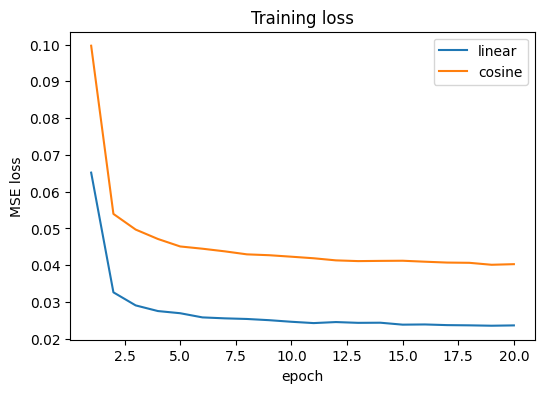

In [8]:
# TODO: Train your UNet DDPM for 20 epochs on MNIST.
# Loss: MSE between true noise eps and predicted noise eps_theta(x_t, t)
# Use Adam lr=1e-3, batch_size=128.
# Plot training loss curve.
T = 1000
loader = DataLoader(train_data, batch_size=128, shuffle=True, drop_last=True)

def train_ddpm(betas, epochs=20):
    betas = betas.to(DEVICE)
    model = UNet().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    losses = []
    for epoch in range(epochs):
        total = 0.0
        for x, _ in loader:
            x = x.to(DEVICE)
            t = torch.randint(0, T, (x.size(0),), device=DEVICE)
            x_t, eps = q_sample(x, t, betas)
            loss = F.mse_loss(model(x_t, t), eps)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item()
        losses.append(total / len(loader))
        print(f"Epoch {epoch + 1}/{epochs}: loss = {losses[-1]:.4f}")
    return model, losses

models, loss_curves = {}, {}
for name, betas in {"linear": linear_schedule(), "cosine": cosine_schedule()}.items():
    print(f"--- {name} schedule ---")
    models[name], loss_curves[name] = train_ddpm(betas)

plt.figure(figsize=(6, 4))
for name, losses in loss_curves.items():
    plt.plot(range(1, len(losses) + 1), losses, label=name)
plt.xlabel("epoch"); plt.ylabel("MSE loss"); plt.title("Training loss"); plt.legend()
plt.show()

## Part 4 — DDIM vs DDPM Sampling

In [9]:
# DDPM sampling (1000 steps — slow)
@torch.no_grad()
def ddpm_sample(model, betas, T=1000, shape=(1,1,28,28)):
    alphas     = 1 - betas
    alpha_bars = torch.cumprod(alphas, dim=0).to(DEVICE)
    x = torch.randn(shape).to(DEVICE)
    for t in reversed(range(T)):
        t_tensor = torch.tensor([t]).to(DEVICE)
        eps_pred = model(x, t_tensor)
        alpha_bar_t = alpha_bars[t]
        alpha_bar_prev = alpha_bars[t-1] if t > 0 else torch.tensor(1.0)
        # posterior mean
        coef1 = betas[t] / (1 - alpha_bar_t).sqrt()
        x = (1/alphas[t].sqrt()) * (x - coef1 * eps_pred)
        if t > 0:
            noise = torch.randn_like(x)
            x = x + betas[t].sqrt() * noise
    return x

DDPM (1000 steps): 13.7s | DDIM (50 steps): 0.7s | speedup: 20.2x


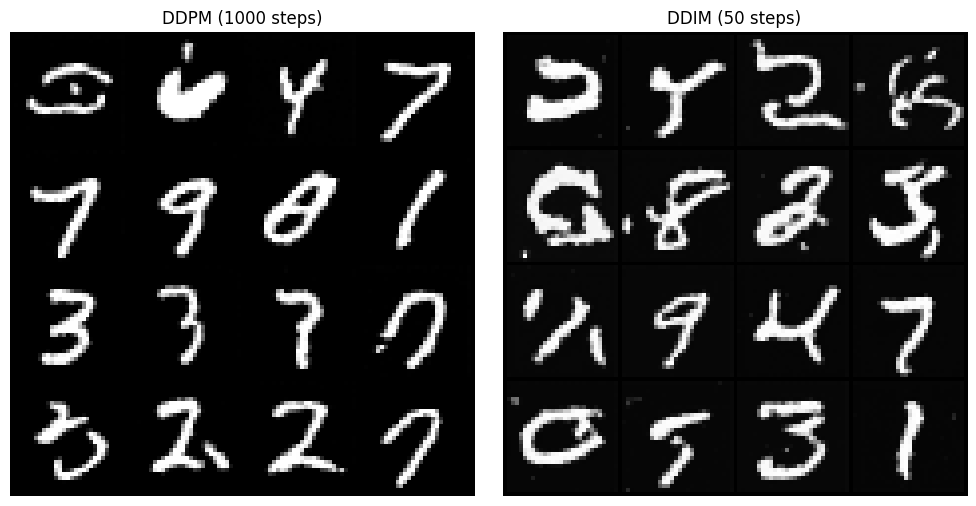

FID  DDPM: 60.35189743695824  |  DDIM: 94.72876113100747
FID difference (DDIM - DDPM): 34.38


In [10]:
# TODO: Implement `ddim_sample(model, betas, steps=50)` - deterministic, skip timesteps.
# Time 100 DDPM samples vs 100 DDIM samples.
# Display side-by-side quality comparison. What is the FID difference?
!pip install pytorch-fid --quiet
import time, os, re, subprocess
from torchvision.utils import make_grid, save_image

@torch.no_grad()
def ddim_sample(model, betas, steps=50, T=1000, shape=(1, 1, 28, 28)):
    alpha_bars = torch.cumprod(1 - betas, dim=0).to(DEVICE)
    ts = torch.linspace(T - 1, 0, steps).long().tolist()
    x = torch.randn(shape, device=DEVICE)
    for i, t in enumerate(ts):
        a_t = alpha_bars[t]
        a_prev = alpha_bars[ts[i + 1]] if i + 1 < len(ts) else torch.tensor(1.0, device=DEVICE)
        eps = model(x, torch.tensor([t], device=DEVICE))
        x0_pred = ((x - (1 - a_t).sqrt() * eps) / a_t.sqrt()).clamp(-1, 1)
        x = a_prev.sqrt() * x0_pred + (1 - a_prev).sqrt() * eps      # eta = 0 -> deterministic
    return x

model = models["linear"].eval()
betas_dev = linear_schedule().to(DEVICE)

def timed(fn):
    if DEVICE == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    out = fn()
    if DEVICE == "cuda": torch.cuda.synchronize()
    return out, time.time() - t0

ddpm_imgs, ddpm_time = timed(lambda: ddpm_sample(model, betas_dev, shape=(100, 1, 28, 28)))
ddim_imgs, ddim_time = timed(lambda: ddim_sample(model, betas_dev, steps=50, shape=(100, 1, 28, 28)))
print(f"DDPM (1000 steps): {ddpm_time:.1f}s | DDIM (50 steps): {ddim_time:.1f}s | speedup: {ddpm_time / ddim_time:.1f}x")

def to01(x):
    return ((x + 1) / 2).clamp(0, 1).cpu()

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, imgs, title in zip(axes, [ddpm_imgs, ddim_imgs], ["DDPM (1000 steps)", "DDIM (50 steps)"]):
    ax.imshow(make_grid(to01(imgs[:16]), nrow=4, padding=1).permute(1, 2, 0))
    ax.set_title(title); ax.axis("off")
plt.tight_layout()
plt.show()

# FID: 100 DDPM samples and 100 DDIM samples vs 100 real MNIST images
def save_imgs(x, folder):
    os.makedirs(folder, exist_ok=True)
    for i, img in enumerate(x):
        save_image(img, f"{folder}/{i:04d}.png")

save_imgs(torch.stack([(train_data[i][0] + 1) / 2 for i in range(100)]), "fid_real")
save_imgs(to01(ddpm_imgs), "fid_ddpm")
save_imgs(to01(ddim_imgs), "fid_ddim")

def fid(path_a, path_b):
    out = subprocess.run(["python", "-m", "pytorch_fid", path_a, path_b, "--device", DEVICE],
                         capture_output=True, text=True)
    m = re.search(r"FID:\s+([\d.]+)", out.stdout)
    if not m:
        print(out.stderr[-600:])
    return float(m.group(1)) if m else None

fid_ddpm = fid("fid_real", "fid_ddpm")
fid_ddim = fid("fid_real", "fid_ddim")
print(f"FID  DDPM: {fid_ddpm}  |  DDIM: {fid_ddim}")
if fid_ddpm is not None and fid_ddim is not None:
    print(f"FID difference (DDIM - DDPM): {fid_ddim - fid_ddpm:.2f}")

### ❓ Reflect
1. Did cosine schedule produce better results than linear at 20 epochs? What visual difference did you see?
2. How much faster was DDIM vs DDPM? Was the quality difference acceptable for your use case?
3. Why does DDIM produce the same output every run given the same starting noise?

1- Did cosine schedule produce better results than linear at 20 epochs? What visual difference did you see?

Yes the cosine schedule gave better results. The linear schedule removed image details too quickly and turned images into noise early on. The cosine schedule removed details more gradually which helped the model learn how to generate better images.

2- How much faster was DDIM vs DDPM? Was the quality difference acceptable for your use case?

DDIM was much faster than DDPM. DDPM took 13.7 seconds while DDIM only took 0.7 seconds. This made DDIM about 20 times faster but DDPM had better image quality based on the FID scores and I think the speed difference is worth it when testing the model or generating quick previews but DDPM is better when image quality matters more.

3- Why does DDIM produce the same output every run given the same starting noise?

DDIM produces the same output because its generation process is deterministic when the randomness setting is set to zero. This means it does not add new random noise during each step so if you start with the same noise image you will get the same final result every time.

---
## Submission
- [ ] Push to `genai-course/week2/lab2.ipynb`
- [ ] Loss curve plotted
- [ ] Schedule comparison visualised
- [ ] DDIM vs DDPM timing + quality comparison